### Import Libraries and Load Data ###

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import itertools
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
file_path = "final_data.csv"  
data = pd.read_csv(file_path)

In [3]:
# Parse the 'date' column and set as index
data['date'] = pd.to_datetime(data['date'], errors='coerce')
data.set_index('date', inplace=True)

### Stationarity Test ###

In [4]:
from statsmodels.tsa.stattools import adfuller

In [7]:
target_variable = 'total CO2 emissions'

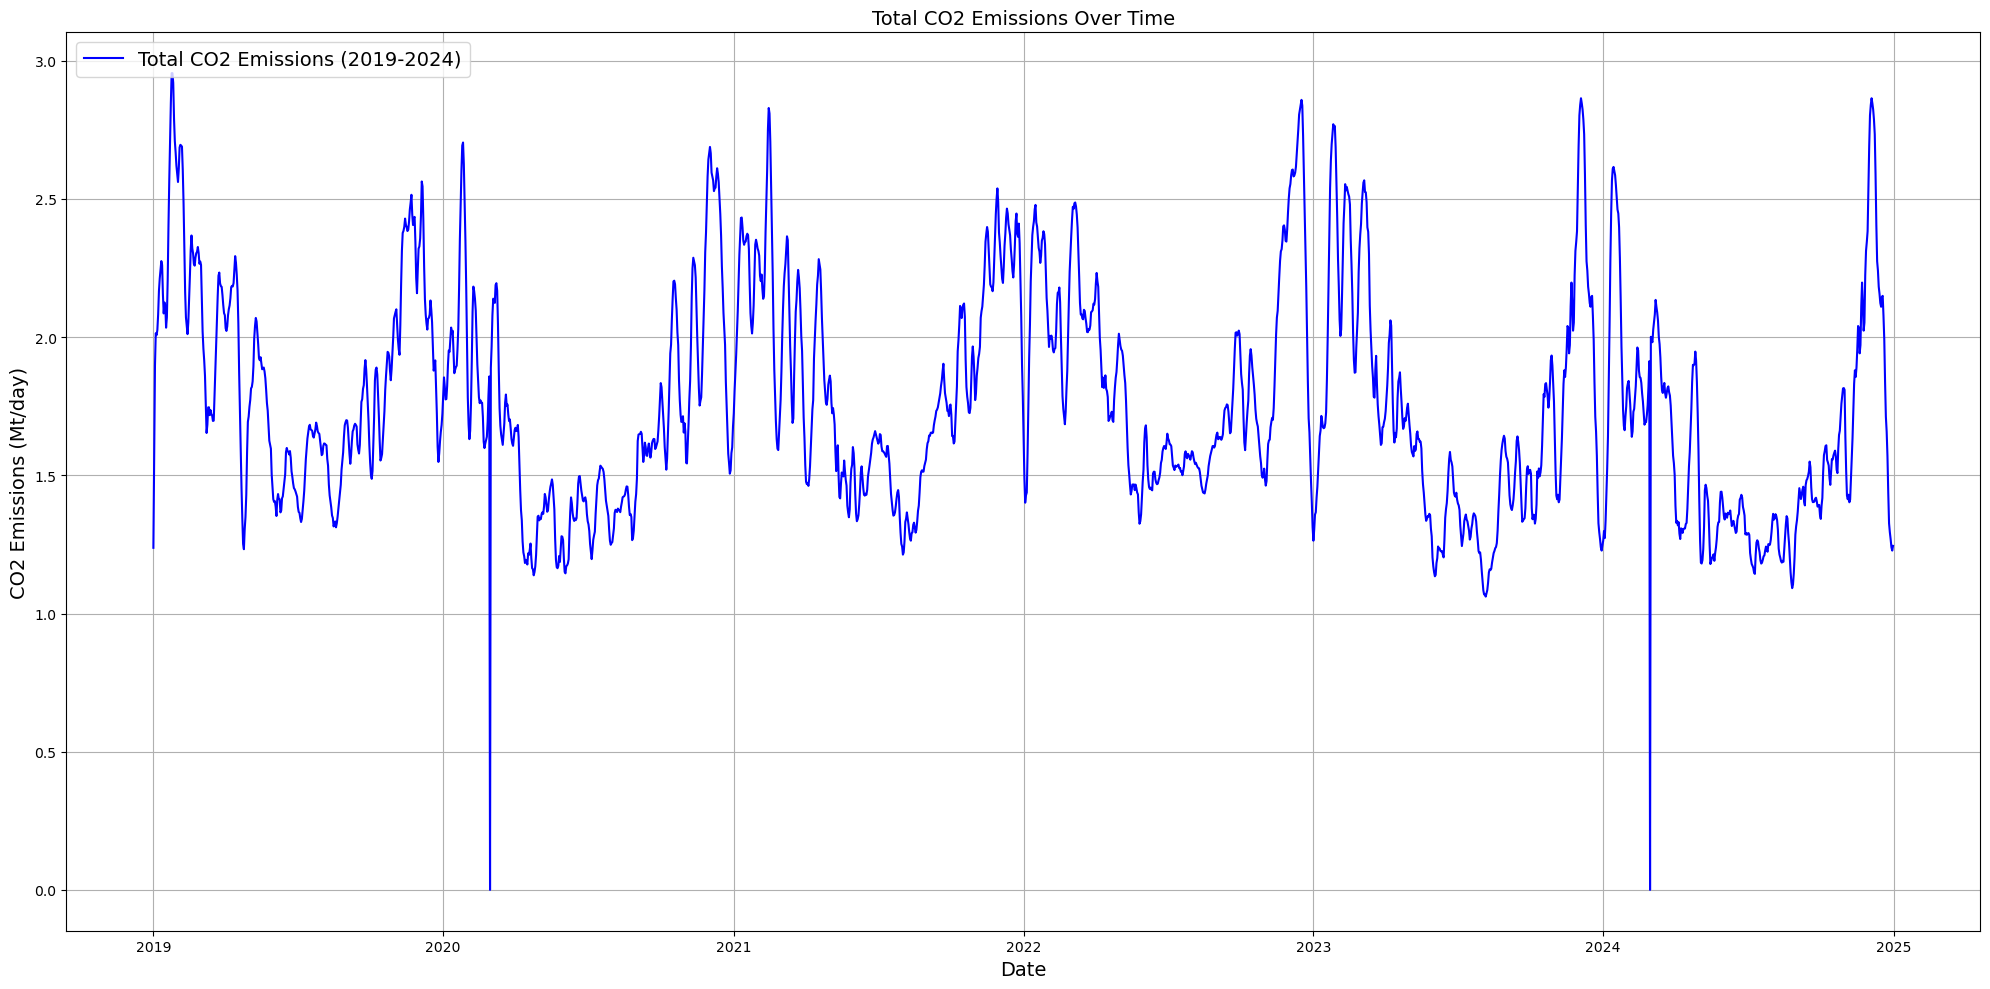

In [6]:
# Simple plot of total CO2 emissions
plt.figure(figsize=(20, 10))
plt.plot(data[target_variable], label='Total CO2 Emissions (2019-2024)', color='blue')
plt.title('Total CO2 Emissions Over Time', fontsize=14)
plt.xlabel('Date', fontsize=14)
plt.ylabel('CO2 Emissions (Mt/day)', fontsize=14)  # Adjust units as per your data
plt.legend(loc='upper left', fontsize=14)
plt.grid(True)
plt.tight_layout()
plt.show()

In [7]:
def test_stationarity(series, name="ADF Test"):
    adf_result = adfuller(series.dropna())
    print(f"\nADF Test for {name}")
    print(f"ADF Statistic: {adf_result[0]}")
    print(f"p-value: {adf_result[1]}")
    
    if adf_result[1] < 0.05:
        print("Result: The series is stationary (reject null hypothesis).")
    else:
        print("Result: The series is non-stationary (fail to reject null hypothesis).")
    
test_stationarity(data[target_variable], name=target_variable)


ADF Test for total CO2 emissions
ADF Statistic: -5.7717628714819265
p-value: 5.371942016323865e-07
Result: The series is stationary (reject null hypothesis).


### Decompose the original Time Series and view all the components

In [7]:
from statsmodels.tsa.seasonal import seasonal_decompose

In [8]:
result_decompose = seasonal_decompose(data[target_variable], model='additive') 

In [9]:
# Extract the components
trend = result_decompose.trend
seasonal = result_decompose.seasonal
residuals = result_decompose.resid

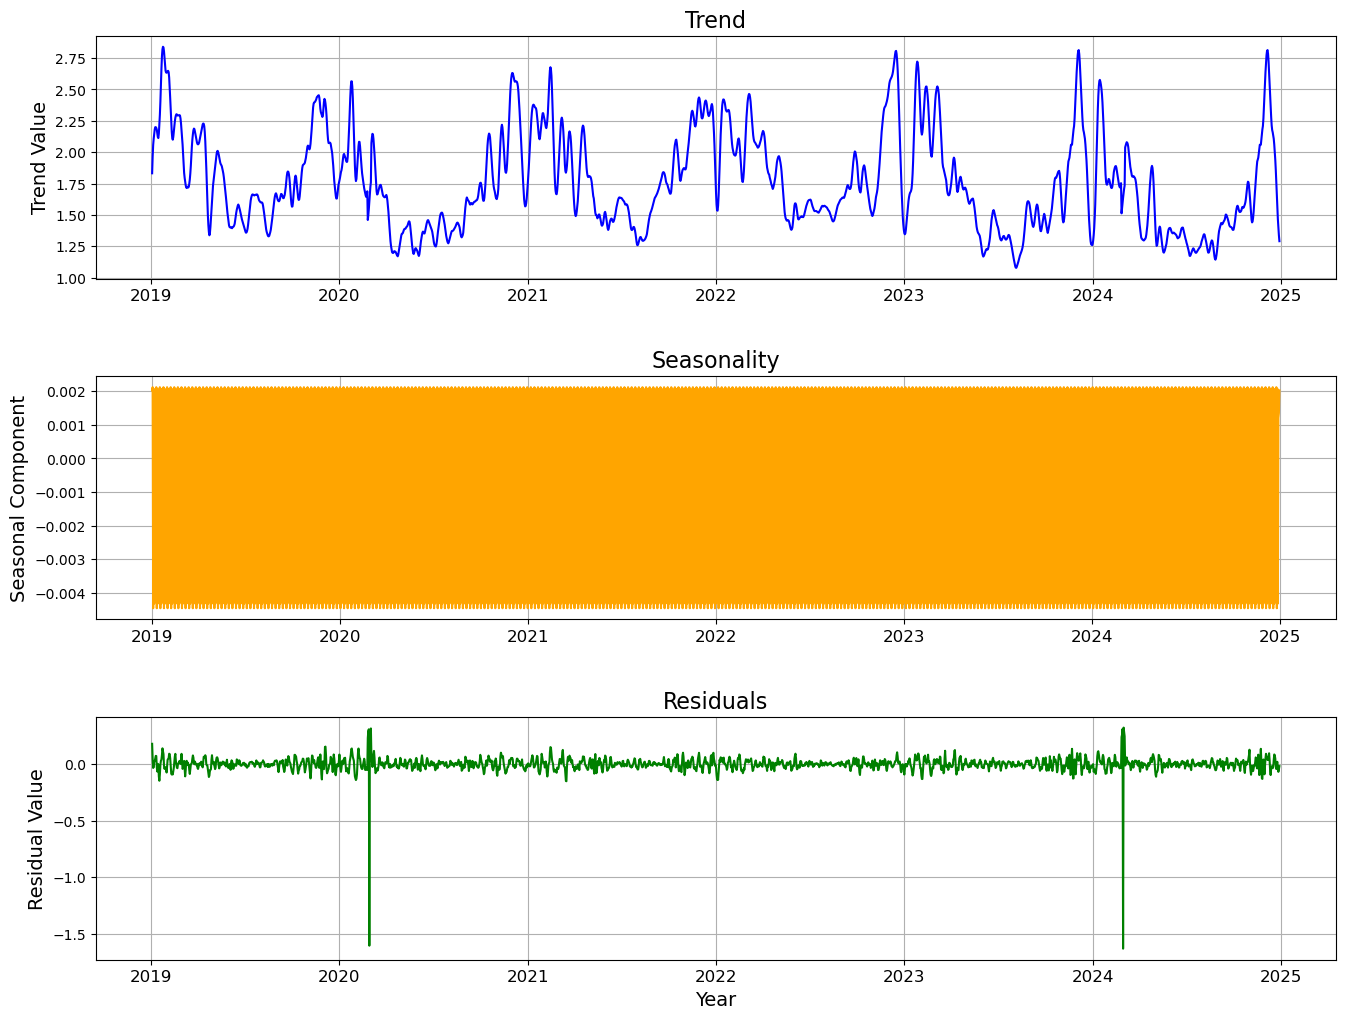

In [22]:
import matplotlib.pyplot as plt

# Create figure and adjust spacing
fig, axes = plt.subplots(3, 1, figsize=(16, 12))  # Share x-axis
fig.subplots_adjust(hspace=0.4)  # Increase space between subplots

# Plot trend
axes[0].plot(trend, color='blue')
axes[0].set_title('Trend', fontsize=16)
axes[0].set_ylabel('Trend Value', fontsize=14)
axes[0].grid()
axes[0].tick_params(axis='x', labelsize=12)  

# Plot seasonality
axes[1].plot(seasonal, color='orange')
axes[1].set_title('Seasonality', fontsize=16)
axes[1].set_ylabel('Seasonal Component', fontsize=14)
axes[1].grid()
axes[1].tick_params(axis='x', labelsize=12)  # Apply to second subplot

# Plot residuals
axes[2].plot(residuals, color='green')
axes[2].set_title('Residuals', fontsize=16)
axes[2].set_xlabel('Year', fontsize=14)  # Set x-axis label on last subplot
axes[2].set_ylabel('Residual Value', fontsize=14)
axes[2].grid()
axes[2].tick_params(axis='x', labelsize=12)  # Apply to third subplot

plt.savefig("plots_co2/04_co2_seasonality.png", dpi=300, bbox_inches='tight')
plt.show()

### Plot ACF and PACF 

In [8]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [9]:
def autocorrelation_plots(timeseries, n_lags, fontsize=14, save_as=None):
    plt.figure(figsize=(15,5))
    plt.subplot(121)
    plot_acf(data[target_variable], ax=plt.gca(), lags=n_lags)
    plt.title('Autocorrelation', fontsize=14)
    plt.xlabel('Number of lags', fontsize=14)
    plt.ylabel('correlation', fontsize=14)
    
    plt.subplot(122)
    plot_pacf(data[target_variable], ax=plt.gca(), lags=n_lags)
    plt.title('Partial Autocorrelation', fontsize=14)
    plt.xlabel('Number of lags', fontsize=14)
    plt.ylabel('correlation', fontsize=14)
    
    if save_as:
        plt.savefig(save_as, dpi=150, bbox_inches='tight')
        
    plt.show()

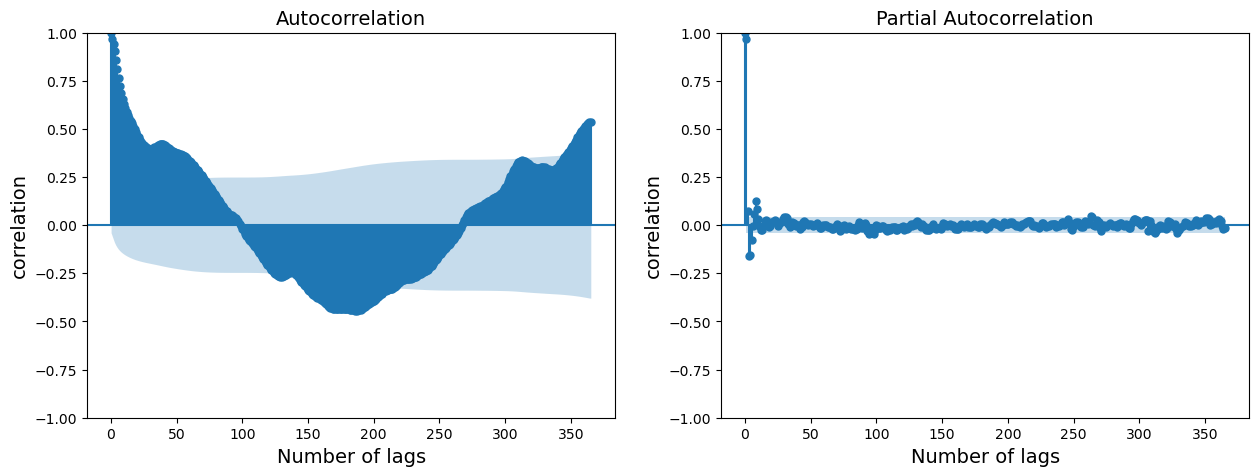

In [10]:
autocorrelation_plots(data[target_variable], 365, save_as="plots_co2/acf_pacf_365.png")

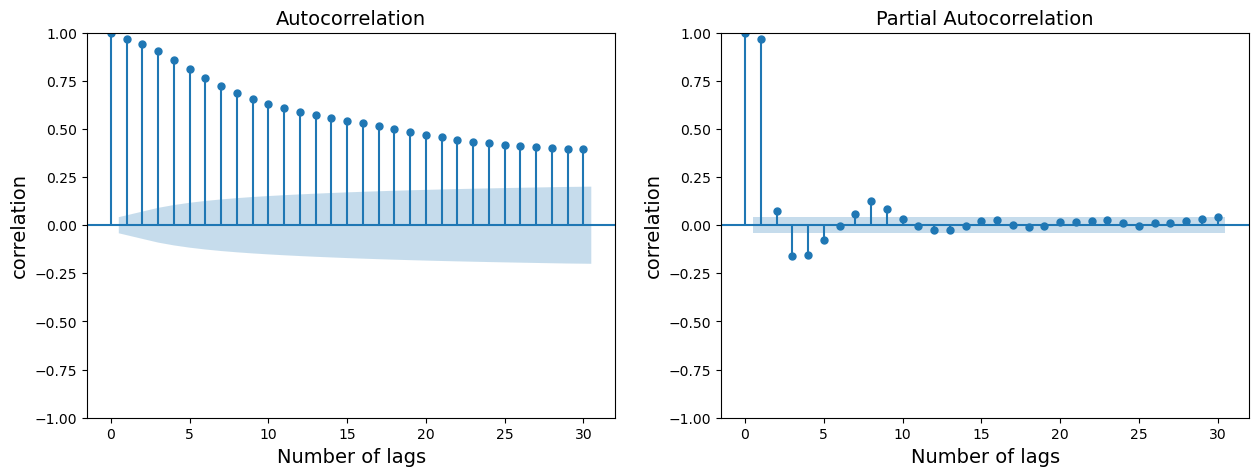

In [11]:
autocorrelation_plots(data[target_variable], 30, save_as="plots_co2/acf_pacf_30.png")

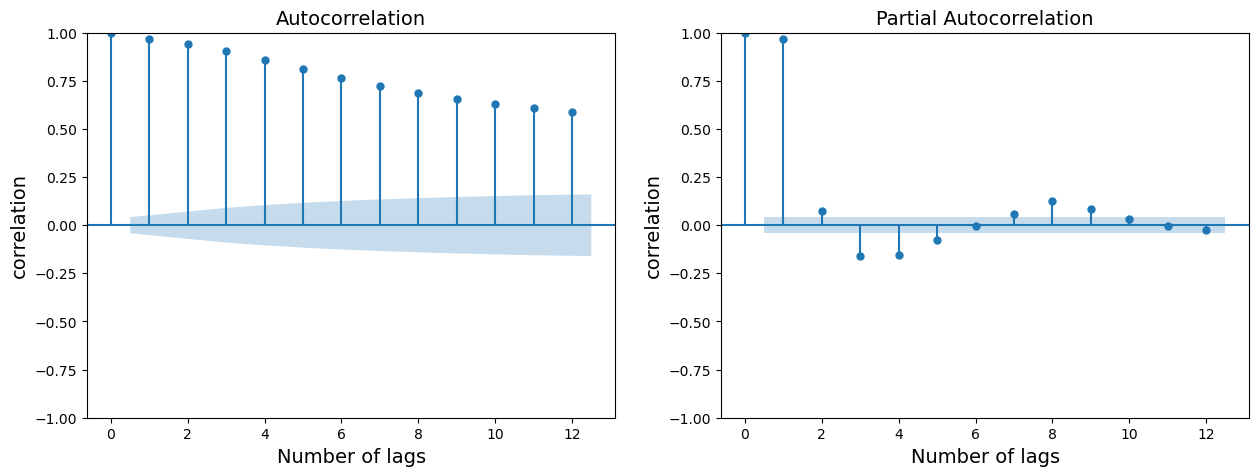

In [12]:
autocorrelation_plots(data[target_variable], 12, save_as="plots_co2/acf_pacf_12.png")

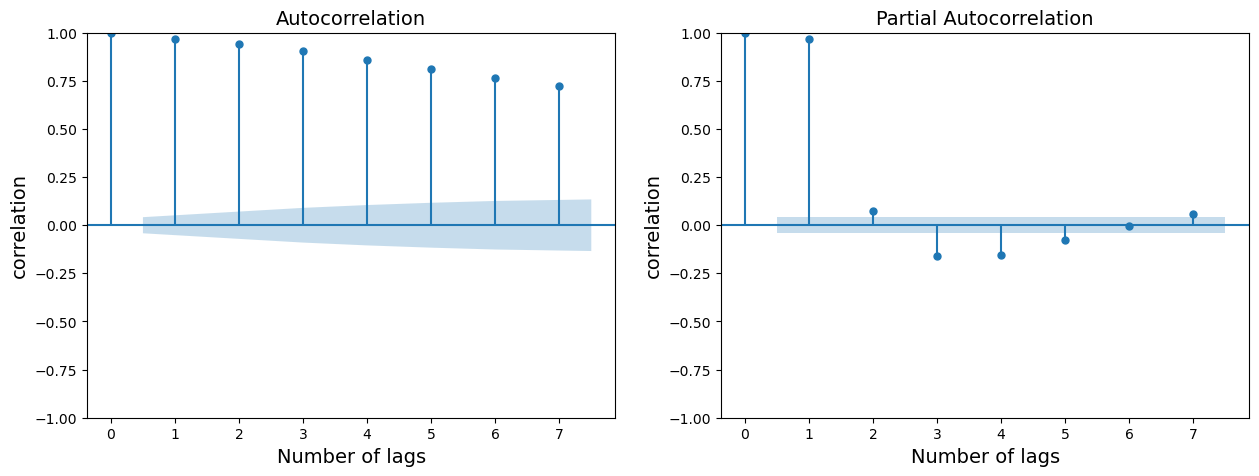

In [13]:
autocorrelation_plots(data[target_variable], 7, save_as="plots_co2/acf_pacf_7.png")

### Split train-test data

In [17]:
import pandas as pd

In [18]:
file_path = "final_data.csv"  
data = pd.read_csv(file_path)

In [19]:
# Convert 'date' column to datetime, auto-detecting the format
data['date'] = pd.to_datetime(data['date'], errors='coerce')

In [20]:
# Set the 'date' column as the index for easy slicing
data.set_index('date', inplace=True)

In [21]:
# Split the dataset
train_data = data.loc['2019-01-01':'2023-12-31']  # Train set
test_data = data.loc['2024-01-01':'2024-12-31']   # Test set

In [22]:
train_data.to_csv("train_data.csv", index=True)
test_data.to_csv("test_data.csv", index=True)

### Determine Seasonality Order

In [178]:
from pmdarima import auto_arima
import pandas as pd
import matplotlib.pyplot as plt

In [179]:
target_variable = 'total CO2 emissions'

In [180]:
train_data = pd.read_csv("train_data.csv", index_col="date", parse_dates=True)
test_data = pd.read_csv("test_data.csv", index_col="date", parse_dates=True)

In [181]:
# Extract the target variable
y_train = train_data[target_variable]
y_test = test_data[target_variable]

In [182]:
auto_model = auto_arima(
    y_train,
    seasonal=True,
    m=12,  
    stepwise=True,
    suppress_warnings=True,
    max_order=None,
)
print(auto_model.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 1826
Model:               SARIMAX(4, 0, 0)   Log Likelihood                1993.049
Date:                Sat, 15 Feb 2025   AIC                          -3974.099
Time:                        13:36:52   BIC                          -3941.039
Sample:                    01-01-2019   HQIC                         -3961.904
                         - 12-31-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0651      0.014      4.626      0.000       0.038       0.093
ar.L1          1.0250      0.005    221.117      0.000       1.016       1.034
ar.L2          0.1740      0.009     19.937      0.0

In [183]:
print("Best SARIMA Order (p, d, q):", auto_model.order)
print("Best Seasonal Order (P, D, Q, m):", auto_model.seasonal_order)

Best SARIMA Order (p, d, q): (4, 0, 0)
Best Seasonal Order (P, D, Q, m): (0, 0, 0, 12)


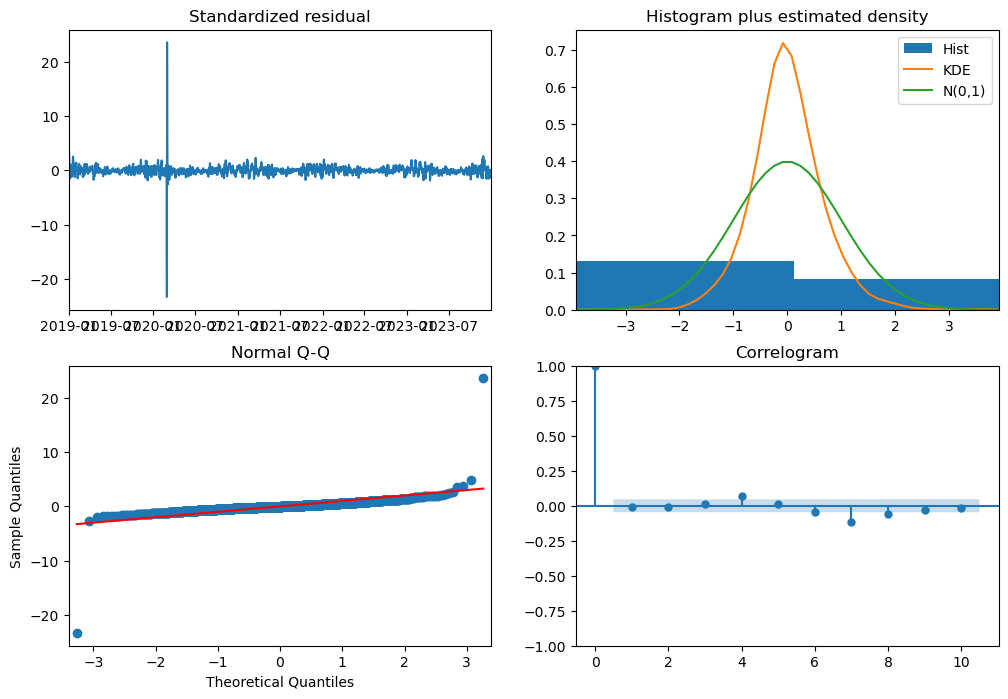

In [184]:
# Plot diagnostics to check model assumptions
auto_model.plot_diagnostics(figsize=(12, 8))
plt.show()

### SARIMA with determined order

In [185]:
# Extract the best order from auto_arima
order = auto_model.order
seasonal_order = auto_model.seasonal_order

In [186]:
# Fit the SARIMAX model
sarimax_model = SARIMAX(
    y_train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


In [187]:
# Print model summary
print(sarimax_model.summary())

                                SARIMAX Results                                
Dep. Variable:     total CO2 emissions   No. Observations:                 1826
Model:                SARIMAX(4, 0, 0)   Log Likelihood                1977.784
Date:                 Sat, 15 Feb 2025   AIC                          -3945.568
Time:                         13:40:43   BIC                          -3918.030
Sample:                     01-01-2019   HQIC                         -3935.409
                          - 12-31-2023                                         
Covariance Type:                   opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.0391      0.005    216.441      0.000       1.030       1.049
ar.L2          0.1726      0.009     19.470      0.000       0.155       0.190
ar.L3         -0.1032      0.019     -5.510 

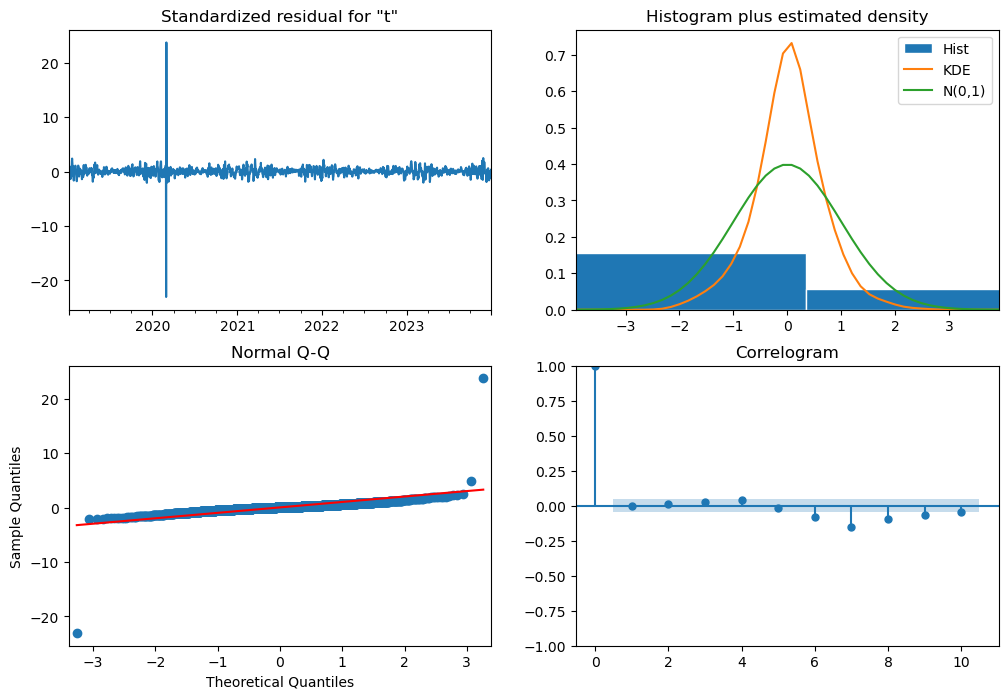

In [188]:
# Plot diagnostics to check model assumptions
sarimax_model.plot_diagnostics(figsize=(12, 8))
plt.show()

In [190]:
# Make predictions on the test set
y_pred = sarimax_model.forecast(steps=len(y_test))  # Predict the test data

In [191]:
# Calculate MAE and RMSE
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

In [192]:
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")

Mean Absolute Error (MAE): 0.8262000320303097
Root Mean Squared Error (RMSE): 0.9293374269744694


In [193]:
# Forecast for the test period (2024)
forecast_steps = len(y_test)  # Number of steps in the test set
forecast = sarimax_model.get_forecast(steps=forecast_steps)
forecast_mean = forecast.predicted_mean
forecast_ci = forecast.conf_int()

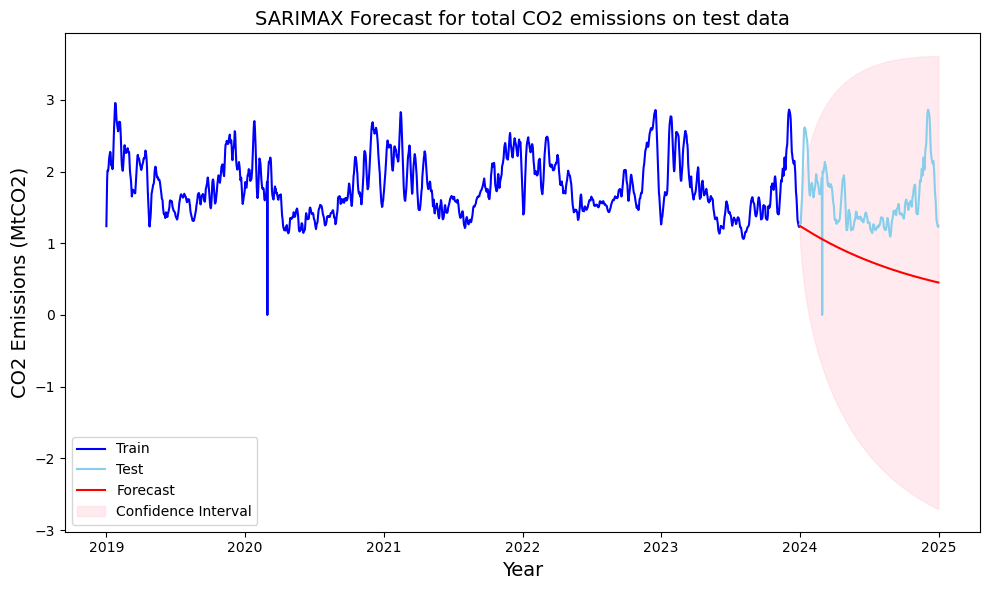

In [296]:
# Plot train data, test data, and forecast
plt.figure(figsize=(10, 6))
# Plot the train data
plt.plot(y_train.index, y_train, label="Train", color="blue")

# Plot the test data (actual values)
plt.plot(y_test.index, y_test, label="Test", color="skyblue")

# Plot the forecast
plt.plot(y_test.index, forecast_mean, label="Forecast", color="red")

# Plot the confidence intervals
plt.fill_between(
    y_test.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    color="pink",
    alpha=0.3,
    label="Confidence Interval"
)

# Add title and labels
plt.title("SARIMAX Forecast for total CO2 emissions on test data", fontsize=14)
plt.xlabel("Year", fontsize=14)
plt.ylabel("CO2 Emissions (MtCO2)", fontsize=14)
plt.legend()
plt.tight_layout()
plt.savefig("plots_co2/sarimax_co2_forecast_on_test.png", bbox_inches='tight')
plt.show()

### SARIMAX with auxiliary variables

In [253]:
# Prepare auxiliary variables (exogenous variables')'
auxiliary_variables = ['natural gas', 'coal', 'Mean_Temperature', 'wind', 'solar', 'population']

In [254]:
exog_train = train_data[auxiliary_variables]
exog_test = test_data[auxiliary_variables]

In [255]:
# Fit SARIMAX with auxiliary variables
sarimax_with_exog = SARIMAX(
    y_train,
    exog=exog_train,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [256]:
# Print model summary
print(sarimax_with_exog.summary())

                                SARIMAX Results                                
Dep. Variable:     total CO2 emissions   No. Observations:                 1826
Model:                SARIMAX(4, 0, 0)   Log Likelihood                1219.417
Date:                 Sat, 15 Feb 2025   AIC                          -2416.833
Time:                         13:46:43   BIC                          -2356.249
Sample:                     01-01-2019   HQIC                         -2394.483
                          - 12-31-2023                                         
Covariance Type:                   opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
natural gas       2.343e-07   1.11e-07      2.102      0.036    1.58e-08    4.53e-07
coal              1.284e-06   5.37e-08     23.921      0.000    1.18e-06    1.39e-06
Mean_Temperature    

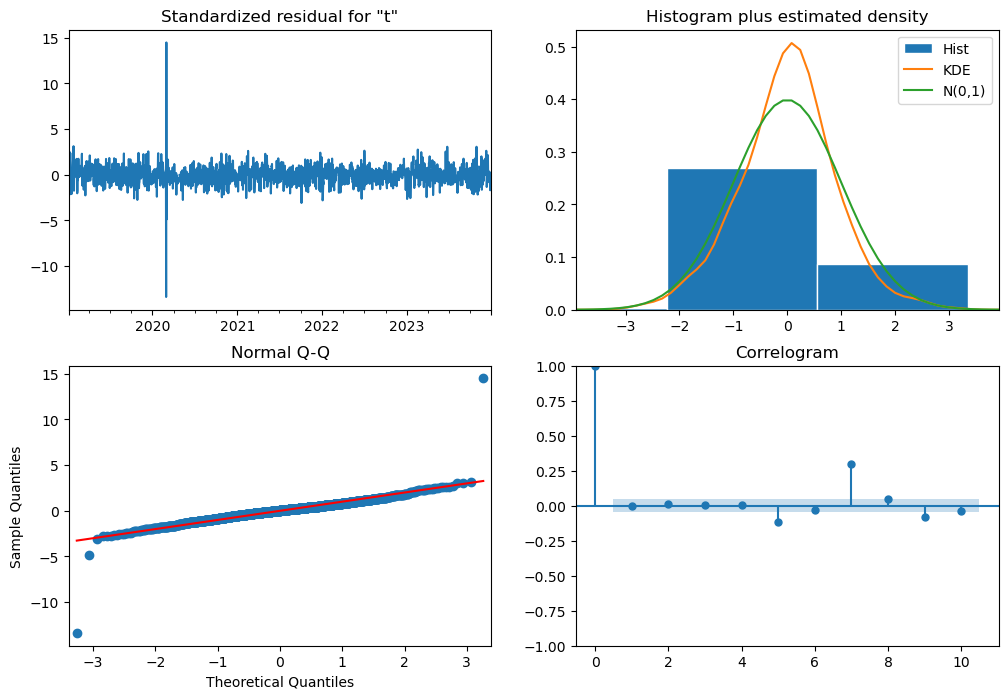

In [257]:
# Plot diagnostics to check model assumptions
sarimax_with_exog.plot_diagnostics(figsize=(12, 8))
plt.show()

In [258]:
# Forecast on the test set with confidence intervals
forecast_results = sarimax_with_exog.get_forecast(steps=len(exog_test), exog=exog_test)
y_pred = forecast_results.predicted_mean
confidence_intervals = forecast_results.conf_int()

In [259]:
# Extract lower and upper bounds for the confidence interval
lower_bound = confidence_intervals.iloc[:, 0]
upper_bound = confidence_intervals.iloc[:, 1]

In [260]:
# Calculate MAE and RMSE
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
# Print MAE and RMSE
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")

Mean Absolute Error (MAE): 0.18190311076477728
Root Mean Squared Error (RMSE): 0.26838296174933435


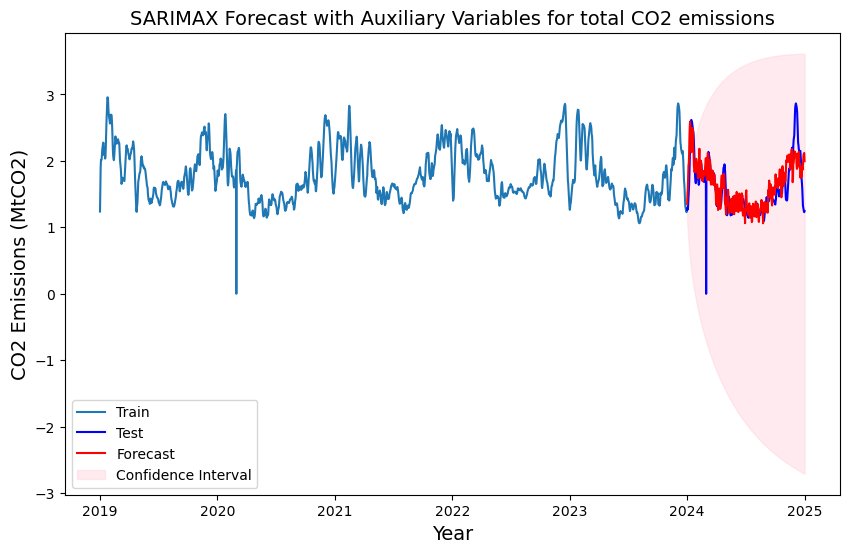

In [293]:
# Plot the forecast vs actuals
plt.figure(figsize=(10, 6))
plt.plot(train_data.index, y_train, label='Train')
plt.plot(test_data.index, y_test, label='Test', color='blue')
plt.plot(test_data.index, y_pred, label='Forecast', color='red')

plt.fill_between(
    y_test.index,
    forecast_ci.iloc[:, 0],
    forecast_ci.iloc[:, 1],
    color="pink",
    alpha=0.3,
    label="Confidence Interval"
)
plt.title(f'SARIMAX Forecast with Auxiliary Variables for {target_variable}', fontsize=14)
plt.xlabel('Year', fontsize=14)
plt.ylabel('CO2 Emissions (MtCO2)', fontsize=14)
plt.legend()
plt.savefig("plots_co2/sarimax_co2_forecast_with_aux.png", bbox_inches='tight')
plt.show()

### Evaluate the Model

In [263]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

In [264]:
# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

In [265]:
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"Mean Absolute Percentage Error (MAPE): {mape}%")

Mean Absolute Error (MAE): 0.18190311076477728
Root Mean Squared Error (RMSE): 0.26838296174933435
Mean Absolute Percentage Error (MAPE): inf%


### Train SARIMAX model on the entire dataset

In [266]:
# Fit SARIMAX on the entire dataset
final_model = SARIMAX(
    data[target_variable],  
    exog=data[auxiliary_variables],  
    order=order,  
    seasonal_order=seasonal_order,  
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)
print("Final SARIMAX model trained on the entire dataset.")

C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


Final SARIMAX model trained on the entire dataset.


C:\Users\Shreya\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [267]:
print(final_model.summary())

                                SARIMAX Results                                
Dep. Variable:     total CO2 emissions   No. Observations:                 2192
Model:                SARIMAX(4, 0, 0)   Log Likelihood                1289.389
Date:                 Sat, 15 Feb 2025   AIC                          -2556.779
Time:                         13:47:29   BIC                          -2494.180
Sample:                     01-01-2019   HQIC                         -2533.898
                          - 12-31-2024                                         
Covariance Type:                   opg                                         
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
natural gas       2.326e-07   1.16e-07      2.004      0.045    5.11e-09     4.6e-07
coal              1.321e-06   5.78e-08     22.860      0.000    1.21e-06    1.43e-06
Mean_Temperature    

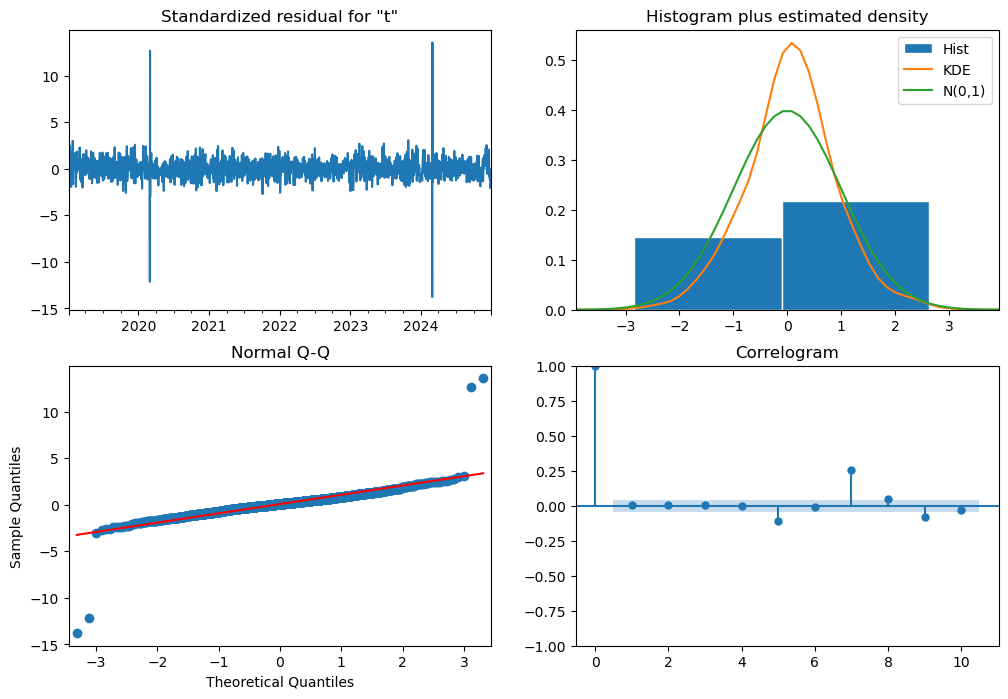

In [268]:
# Plot diagnostics to check model assumptions
final_model.plot_diagnostics(figsize=(12, 8))
plt.show()

For SARIMAX Model, the only requirement to use an exogenous variable is that, we should know the value of the variable during the forecast period as well.

In [269]:
import pandas as pd
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

In [270]:
file_path = "final_data.csv"  
data = pd.read_csv(file_path)

# Parse the 'date' column and set as index
data['date'] = pd.to_datetime(data['date'], errors='coerce')
data.set_index('date', inplace=True)

In [272]:
# Decompose each auxiliary variable to extract trends and seasonality
forecast_days = pd.date_range('2025-01-01', '2026-12-31', freq='D')
projected_aux_vars = pd.DataFrame({'date': forecast_days})
projected_aux_vars.set_index('date', inplace=True)

In [273]:
for aux_var in auxiliary_variables:
    # Decompose the auxiliary variable (last 3 years)
    result = seasonal_decompose(data[aux_var][-365*3:], model='additive', period=365)

    # Extract and extend the seasonal component
    seasonal_component = result.seasonal[-365:]  # Last year of seasonality
    seasonal_df = pd.DataFrame({'day_of_year': seasonal_component.index.dayofyear, aux_var: seasonal_component.values})

    # Extend the seasonal component for the forecast period
    seasonal_forecast = pd.DataFrame({'date': forecast_days})
    seasonal_forecast['day_of_year'] = seasonal_forecast['date'].dt.dayofyear
    seasonal_forecast = seasonal_forecast.merge(seasonal_df, on='day_of_year', how='left')
    seasonal_forecast[aux_var] = seasonal_forecast[aux_var].fillna(method='ffill').fillna(method='bfill')

    # Add the seasonal forecast to the final DataFrame
    projected_aux_vars[aux_var] = seasonal_forecast[aux_var].values

    # Add the trend component (if any)
    trend_component = result.trend.dropna().values
    if len(trend_component) > 0:
        # Linearly extrapolate the trend for the forecast period
        trend_slope = (trend_component[-1] - trend_component[0]) / len(trend_component)
        trend_forecast = trend_component[-1] + trend_slope * range(1, len(forecast_days) + 1)
        projected_aux_vars[aux_var] += trend_forecast

In [274]:
# Compute and add the seasonal index
# Decompose the target variable to extract the seasonal component
result = seasonal_decompose(data[target_variable][-365*3:], model='additive', period=365)
seasonal_index = result.seasonal[-365:]  # Last year of seasonality

In [275]:
# Create seasonal index for the forecast period
seasonal_index_df = seasonal_index.reset_index()
seasonal_index_df.columns = ['date', 'seasonal_index']
seasonal_index_df['date'] = pd.to_datetime(seasonal_index_df['date'], errors='coerce')
seasonal_index_df['day_of_year'] = seasonal_index_df['date'].dt.dayofyear

In [276]:
# Extend the seasonal index for the forecast period
seasonal_forecast = pd.DataFrame({'date': forecast_days})
seasonal_forecast['day_of_year'] = seasonal_forecast['date'].dt.dayofyear
seasonal_forecast = seasonal_forecast.merge(
    seasonal_index_df[['day_of_year', 'seasonal_index']],
    on='day_of_year',
    how='left'
)
seasonal_forecast['seasonal_index'] = seasonal_forecast['seasonal_index'].fillna(method='ffill').fillna(method='bfill')

In [277]:
# Add the seasonal index to the final DataFrame
projected_aux_vars['seasonal_index'] = seasonal_forecast['seasonal_index'].values

In [278]:
# Verify the `future_exog` DataFrame
future_exog = projected_aux_vars.copy()
print("Future Auxiliary Variables for Forecast Period:")
print(future_exog.head())
print(future_exog.tail())

Future Auxiliary Variables for Forecast Period:
              natural gas           coal  Mean_Temperature           wind  \
date                                                                        
2025-01-01  105940.557347  165629.388113          8.985626  734712.942623   
2025-01-02  105982.258512  165373.826689          8.986464  734757.831572   
2025-01-03  116398.028513  236466.577252          7.846070  714520.006138   
2025-01-04  132220.826254  186332.640828          7.752525  839067.418717   
2025-01-05  153439.322282  281690.046528          8.105007  631484.961091   

                   solar  population  seasonal_index  
date                                                  
2025-01-01  40992.444660   84.860020       -0.417311  
2025-01-02  41020.772127   84.860942       -0.417311  
2025-01-03  57772.524937   84.861382       -0.402307  
2025-01-04  39244.006172   84.861824       -0.366038  
2025-01-05  43270.907270   84.862270       -0.291035  
              natural gas  

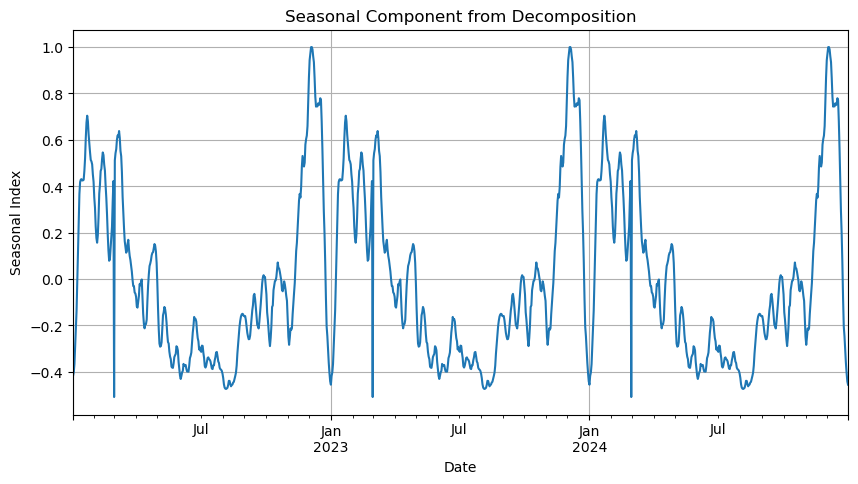

In [279]:
# Plot seasonal components for verification
plt.figure(figsize=(10, 5))
result.seasonal.plot(title="Seasonal Component from Decomposition")
plt.xlabel("Date")
plt.ylabel("Seasonal Index")
plt.grid()
plt.show()

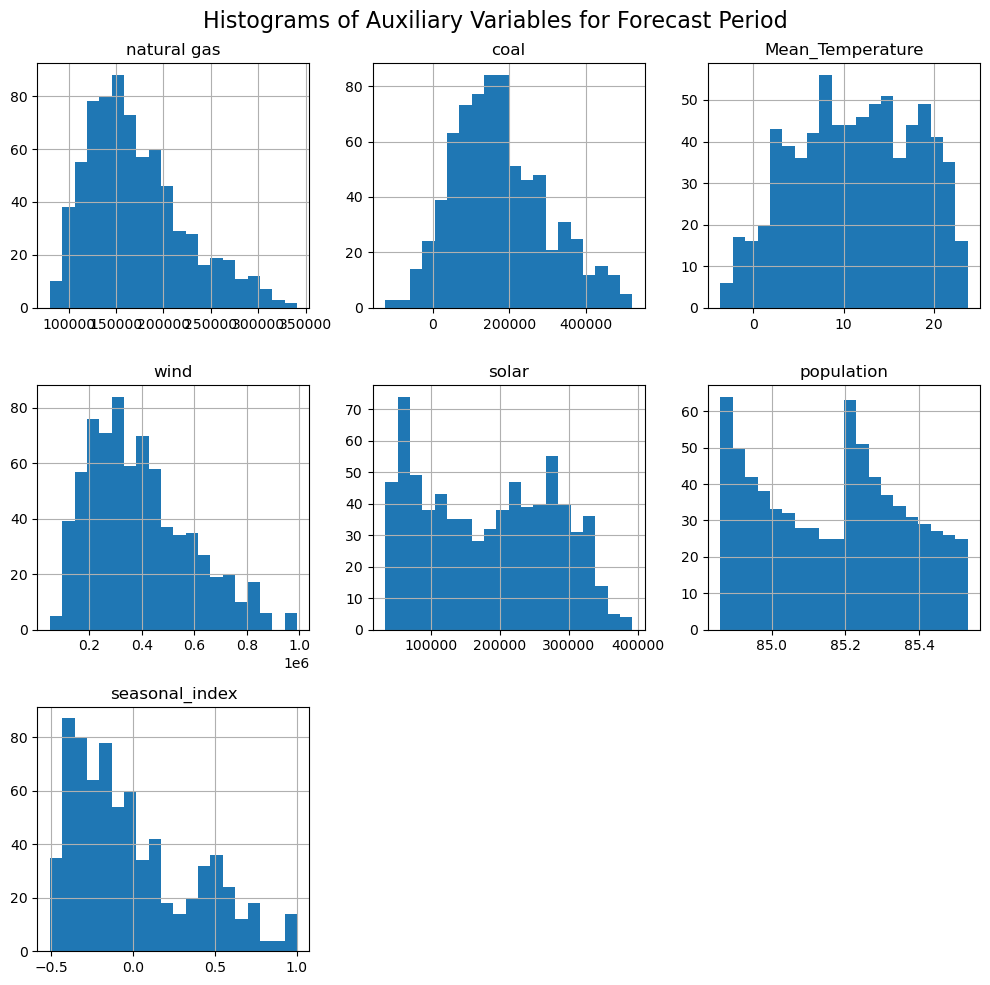

In [280]:
# Plot histograms of auxiliary variables for the forecast period
future_exog.hist(bins=20, figsize=(10, 10))
plt.suptitle("Histograms of Auxiliary Variables for Forecast Period", fontsize=16)
plt.tight_layout()
plt.show()

### Predicting CO2 emissions for the next 2 years

In [281]:
# Ensure future_exog contains only the columns used during training
future_exog = future_exog[auxiliary_variables]  # Filter only the original auxiliary variables

In [282]:
# Forecast for the next 2 years (2025–2026)
forecast_steps = future_exog.shape[0]  # Number of days in the forecast period (e.g., 730 for 2025–2026)
forecast_results = final_model.get_forecast(steps=forecast_steps, exog=future_exog)

In [283]:
# Extract forecasted values and confidence intervals
forecasted_mean = forecast_results.predicted_mean
forecasted_ci = forecast_results.conf_int()

In [284]:
# Combine forecast results into a single DataFrame
forecast_df = pd.DataFrame({
    'Forecasted': forecasted_mean,
    'Lower Bound': forecasted_ci.iloc[:, 0],
    'Upper Bound': forecasted_ci.iloc[:, 1]
}, index=future_exog.index)

In [285]:
# Display forecast results
print("Forecast for 2025–2026:")
print(forecast_df.head())

Forecast for 2025–2026:
            Forecasted  Lower Bound  Upper Bound
date                                            
2025-01-01    1.132507     0.869172     1.395842
2025-01-02    1.286022     0.933813     1.638232
2025-01-03    1.510428     1.120830     1.900025
2025-01-04    1.564052     1.156818     1.971285
2025-01-05    1.681064     1.265880     2.096249


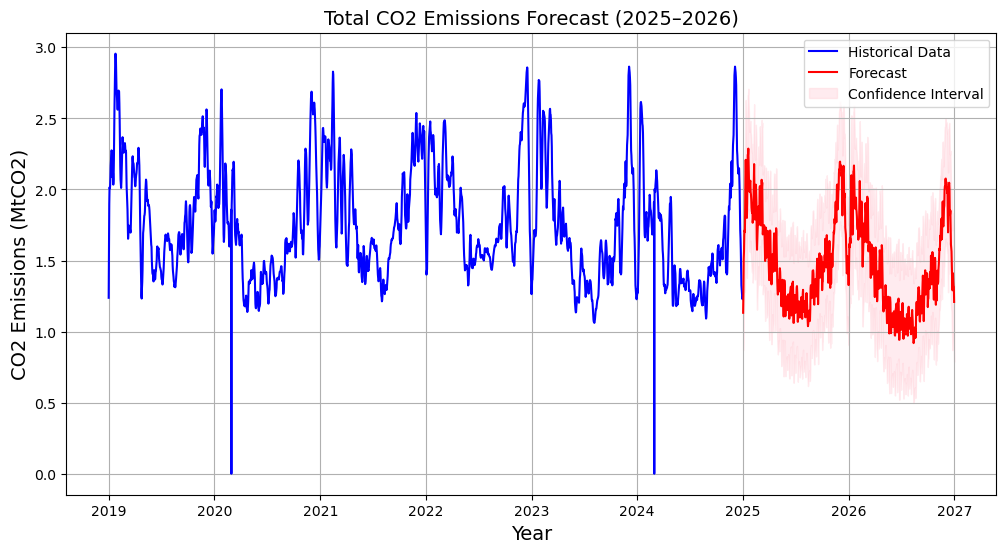

In [295]:
# Plot the forecast
plt.figure(figsize=(12, 6))
plt.plot(data[target_variable], label='Historical Data', color='blue')
plt.plot(forecasted_mean, label='Forecast', color='red')
plt.fill_between(forecast_df.index, forecast_df['Lower Bound'], forecast_df['Upper Bound'], color='pink', alpha=0.3, label='Confidence Interval')
plt.title('Total CO2 Emissions Forecast (2025–2026)', fontsize=14)
plt.xlabel('Year', fontsize=14)
plt.ylabel('CO2 Emissions (MtCO2)', fontsize=14)
plt.legend()
plt.grid()
plt.savefig("plots_co2/sarimax_co2_final_forecast.png", bbox_inches='tight')
plt.show()

In [229]:
# Summarize Forecast Results
forecast_summary = forecast_df.describe()

In [230]:
# Print the key statistics
print("Summary Statistics for Forecasted CO2 Emissions (2025–2026):")
print(forecast_summary)

Summary Statistics for Forecasted CO2 Emissions (2025–2026):
       Forecasted  Lower Bound  Upper Bound
count  730.000000   730.000000   730.000000
mean     1.185474     0.683306     1.687641
std      0.336988     0.337261     0.336868
min      0.547017     0.044401     1.049633
25%      0.919618     0.417002     1.422234
50%      1.113719     0.611103     1.615587
75%      1.411904     0.915127     1.909509
max      2.032487     1.529876     2.535098


In [231]:
# Display summary statistics for confidence intervals
ci_summary = forecast_df[['Lower Bound', 'Upper Bound']].describe()
print("\nSummary of Confidence Intervals:")
print(ci_summary)


Summary of Confidence Intervals:
       Lower Bound  Upper Bound
count   730.000000   730.000000
mean      0.683306     1.687641
std       0.337261     0.336868
min       0.044401     1.049633
25%       0.417002     1.422234
50%       0.611103     1.615587
75%       0.915127     1.909509
max       1.529876     2.535098


In [232]:
forecast_df.to_csv("forecasted_CO2_emissions_2025_2026.csv", index=True)
print("Forecast results saved to 'forecasted_CO2_emissions_2025_2026.csv'")

Forecast results saved to 'forecasted_CO2_emissions_2025_2026.csv'
